# Experiment 11 — Analysis and Implementation of Performance Metrics

**Aim:** Evaluate Logistic Regression and a Decision Tree on the Breast Cancer Wisconsin Diagnostic dataset using confusion matrices, classification metrics and ROC-AUC.

**Theory:** Accuracy measures all correct predictions; precision, recall and F1 describe positive-class performance. The ROC curve compares sensitivity with false-positive rate across thresholds.

**Positive class:** Malignant (label 0). In a medical screening context, recall for malignant cases is important because a false negative can delay treatment.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import (accuracy_score, auc, confusion_matrix, f1_score, precision_score, recall_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

SEED = 42
ROOT = Path.cwd()
if not (ROOT / 'datasets').is_dir():
    ROOT = ROOT.parent
FIGURES = ROOT / 'outputs' / 'figures'
RESULTS = ROOT / 'outputs' / 'results'
FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
csv_path = ROOT / 'datasets' / 'breast-cancer.csv'
if csv_path.is_file():
    local = pd.read_csv(csv_path)
    required = {'diagnosis'}
    if required.issubset(local.columns) and set(local['diagnosis'].dropna().unique()) == {'M', 'B'}:
        X = local.drop(columns=['diagnosis', 'id'], errors='ignore').select_dtypes(include='number')
        y = local['diagnosis'].map({'M': 0, 'B': 1}).astype(int)
        if X.shape[1] == 0:
            raise ValueError('The supplied breast-cancer CSV has no numeric predictor columns.')
        data_source = 'datasets/breast-cancer.csv'
    else:
        print('Supplied CSV schema is incompatible; using scikit-learn Breast Cancer Wisconsin data.')
        dataset = load_breast_cancer()
        X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
        y = pd.Series(dataset.target, name='diagnosis')
        data_source = 'sklearn.datasets.load_breast_cancer()'
else:
    dataset = load_breast_cancer()
    X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
    y = pd.Series(dataset.target, name='diagnosis')
    data_source = 'sklearn.datasets.load_breast_cancer()'

print('Dataset source:', data_source)
print('Feature matrix shape:', X.shape)
print('Class counts (0 = malignant, 1 = benign):')
print(y.value_counts().sort_index().rename(index={0: 'malignant', 1: 'benign'}))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=SEED)),
    'Decision Tree': DecisionTreeClassifier(random_state=SEED, max_depth=5),
}
for model in models.values():
    model.fit(X_train, y_train)
print(f'Train/test rows: {len(X_train)}/{len(X_test)}')

Dataset source: datasets/breast-cancer.csv
Feature matrix shape: (569, 30)
Class counts (0 = malignant, 1 = benign):
diagnosis
malignant    212
benign       357
Name: count, dtype: int64
Train/test rows: 455/114


## Confusion matrices and library/manual metrics

The confusion matrices use label order `[0, 1]`. Thus `TP = cm[0, 0]` and `FN = cm[0, 1]` for malignant as the positive class.

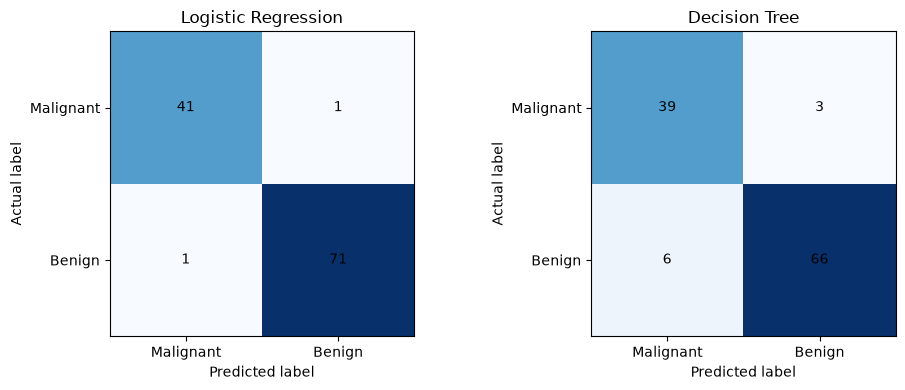

Library metrics and manually calculated metrics:
                     Accuracy  Precision (malignant)  Recall (malignant)  F1 (malignant)  Manual Accuracy  Manual Precision (malignant)  Manual Recall (malignant)  Manual F1 (malignant)  AUC (malignant)
Model                                                                                                                                                                                                     
Logistic Regression    0.9825                 0.9762              0.9762          0.9762           0.9825                        0.9762                     0.9762                 0.9762           0.9954
Decision Tree          0.9211                 0.8667              0.9286          0.8966           0.9211                        0.8667                     0.9286                 0.8966           0.9163


In [2]:
def manual_metrics(matrix):
    true_positive = matrix[0, 0]
    false_negative = matrix[0, 1]
    false_positive = matrix[1, 0]
    true_negative = matrix[1, 1]
    accuracy = (true_positive + true_negative) / matrix.sum()
    precision = true_positive / (true_positive + false_positive) if true_positive + false_positive else 0.0
    recall = true_positive / (true_positive + false_negative) if true_positive + false_negative else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {'Accuracy': accuracy, 'Precision (malignant)': precision, 'Recall (malignant)': recall, 'F1 (malignant)': f1}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
rows = []
roc_data = []
for axis, (name, model) in zip(axes, models.items()):
    predicted = model.predict(X_test)
    matrix = confusion_matrix(y_test, predicted, labels=[0, 1])
    axis.imshow(matrix, cmap='Blues')
    axis.set_title(name)
    axis.set_xlabel('Predicted label')
    axis.set_ylabel('Actual label')
    axis.set_xticks([0, 1], ['Malignant', 'Benign'])
    axis.set_yticks([0, 1], ['Malignant', 'Benign'])
    for (row, column), count in np.ndenumerate(matrix):
        axis.text(column, row, str(count), ha='center', va='center')
    library = {
        'Accuracy': accuracy_score(y_test, predicted),
        'Precision (malignant)': precision_score(y_test, predicted, pos_label=0, zero_division=0),
        'Recall (malignant)': recall_score(y_test, predicted, pos_label=0, zero_division=0),
        'F1 (malignant)': f1_score(y_test, predicted, pos_label=0, zero_division=0),
    }
    manual = manual_metrics(matrix)
    if not np.allclose(list(library.values()), list(manual.values())):
        raise AssertionError(f'Manual metric calculation does not match scikit-learn for {name}.')
    rows.append({'Model': name, **library, **{f'Manual {key}': value for key, value in manual.items()}})
    malignant_index = list(model.classes_).index(0)
    malignant_scores = model.predict_proba(X_test)[:, malignant_index]
    fpr, tpr, _ = roc_curve((y_test == 0).astype(int), malignant_scores)
    model_auc = auc(fpr, tpr)
    roc_data.append((name, fpr, tpr, model_auc))
    rows[-1]['AUC (malignant)'] = model_auc
fig.tight_layout()
fig.savefig(FIGURES / 'exp11_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

comparison = pd.DataFrame(rows).set_index('Model')
print('Library metrics and manually calculated metrics:')
print(comparison.to_string(float_format=lambda value: f'{value:.4f}'))
comparison.to_csv(RESULTS / 'exp11_metric_comparison.csv')

## ROC curves and conclusion

Both ROC curves use the model's probability of malignancy. The higher-recall model misses fewer malignant cases at the selected classification threshold.

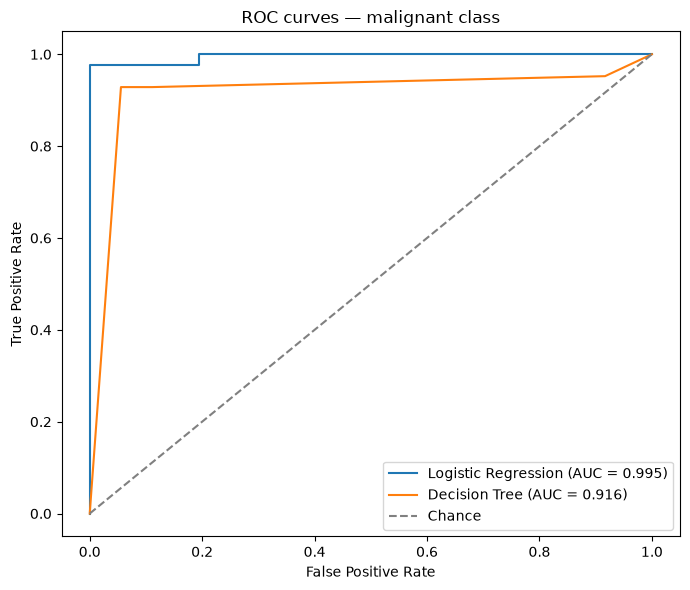

AUC comparison:
                     AUC (malignant)
Model                               
Logistic Regression           0.9954
Decision Tree                 0.9163
Conclusion: Logistic Regression has the highest AUC (0.995) and Logistic Regression has the highest malignant recall (0.976). High malignant recall reduces the risk of missed cancer cases.


In [3]:
fig, axis = plt.subplots(figsize=(7, 6))
for name, false_positive_rate, true_positive_rate, model_auc in roc_data:
    axis.plot(false_positive_rate, true_positive_rate, label=f'{name} (AUC = {model_auc:.3f})')
axis.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
axis.set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC curves — malignant class')
axis.legend(loc='lower right')
fig.tight_layout()
fig.savefig(FIGURES / 'exp11_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

auc_table = pd.DataFrame([{'Model': name, 'AUC (malignant)': model_auc} for name, _, _, model_auc in roc_data]).set_index('Model')
print('AUC comparison:')
print(auc_table.to_string(float_format=lambda value: f'{value:.4f}'))
best_auc_model = auc_table['AUC (malignant)'].idxmax()
best_recall_model = comparison['Recall (malignant)'].idxmax()
print(f'Conclusion: {best_auc_model} has the highest AUC ({auc_table.loc[best_auc_model, "AUC (malignant)"]:.3f}) and {best_recall_model} has the highest malignant recall ({comparison.loc[best_recall_model, "Recall (malignant)"]:.3f}). High malignant recall reduces the risk of missed cancer cases.')